In [1]:
%pip -q install requests pandas pyarrow duckdb psycopg2-binary sqlalchemy

In [2]:
# Class data access: Polymarket only
# Access expires October 29, 2026 at 11:59 pm PDT.
# Password is kept only in runtime memory.
import base64
from getpass import getpass
import pandas as pd
import duckdb
from sqlalchemy import create_engine, text
from sqlalchemy.engine import URL

HTTP_USER = "polymarketdatabase"
BASE = "https://d1yyqbluk0oz0t.cloudfront.net/"
DEFAULT_FILE = "events-2026-05-30T21.parquet"

password = getpass("Polymarket password from course announcement: ")

# Postgres (read-only)
engine = create_engine(
    URL.create("postgresql+psycopg2",
               username="polymarketdatabase.merbqatlxbrcvtbnuaqe",
               password=password,
               host="aws-0-us-west-2.pooler.supabase.com",
               port=6543, database="postgres"),
    connect_args={"sslmode": "require", "connect_timeout": 15,
                  "options": "-c default_transaction_read_only=on -c statement_timeout=60000"},
    pool_pre_ping=True,
)

# Remote Parquet via DuckDB
parquet_db = duckdb.connect()
parquet_db.execute("INSTALL httpfs; LOAD httpfs;")
token = base64.b64encode(f"{HTTP_USER}:{password}".encode()).decode()
parquet_db.execute(f"""
    CREATE OR REPLACE SECRET polymarket_access (
        TYPE http, SCOPE '{BASE}',
        EXTRA_HTTP_HEADERS MAP {{'Authorization': 'Basic {token}'}}
    )
""")
del token, password

def query_db(sql, params=None):
    """Run a read-only SQL query and return a pandas DataFrame."""
    with engine.connect() as connection:
        return pd.read_sql_query(text(sql), connection, params=params)

def preview_parquet(filename=DEFAULT_FILE, limit=100):
    """Read a bounded preview of a remote Parquet file."""
    if not isinstance(limit, int) or not 1 <= limit <= 10000:
        raise ValueError("limit must be an integer from 1 to 10000")
    if "/" in filename or ".." in filename:
        raise ValueError("Use a filename from the class dataset")
    return parquet_db.execute(
        "SELECT * FROM read_parquet(?) LIMIT ?", [BASE + filename, limit]
    ).df()

print("Polymarket connections configured.")

Polymarket password from course announcement: ··········
Polymarket connections configured.


In [3]:
import re

def read_wallet_trades(date, where="", limit=None):
    """Load one day of wallet trades, e.g. read_wallet_trades('2026-10-03')."""
    if not re.fullmatch(r"\d{4}-\d{2}-\d{2}", date):
        raise ValueError("date must look like 2026-10-03")
    sql = f"SELECT * FROM read_parquet('{BASE}wallet_trades/trades-{date}.parquet')"
    if where:
        sql += f" WHERE {where}"
    if limit:
        sql += f" LIMIT {int(limit)}"
    return parquet_db.execute(sql).df()

trades = read_wallet_trades('2026-10-03')
print(trades.shape)
display(trades.head())

(970880, 8)


,wallet,market,time,side,outcome,price,size,dollars
0,0xeb10e414237546b18c6f1a87c2b5a7193f67aed3,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 12:45:35+00:00,BUY,Yes,0.37,4.756757,1.760000
1,0xbbecb03a1e605571630e08545809358781ae323d,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 12:45:35+00:00,BUY,Yes,0.37,115.000000,42.550000
2,0x7d4228c8e41f12fdc750fa852ac5f98132a10a1a,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 08:29:14+00:00,SELL,No,0.63,60.000000,37.800000
3,0xa67f112268a42b518edf6f4152bfe3ef6bb4afd4,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 08:29:14+00:00,BUY,Yes,0.37,20.000000,7.400000
4,0x143088b03e8512fc47a40ef8d67b82fa54318a86,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 06:44:26+00:00,BUY,No,0.66,65.151514,42.999999


In [4]:
# Verify the Polymarket database and Parquet file.
from IPython.display import display

print("POLYMARKET — PostgreSQL")
try:
    market_sample = query_db(
        "SELECT slug, title, best_bid, best_ask FROM public.markets LIMIT 10")
    display(market_sample)
except Exception as exc:
    print(f"Database check failed: {type(exc).__name__}")

print("POLYMARKET — Parquet")
try:
    parquet_sample = preview_parquet()
    print(f"Loaded {len(parquet_sample)} preview rows")
    display(parquet_sample.head())
except Exception as exc:
    print(f"Parquet check failed: {type(exc).__name__}")

# Analysis examples:
# query_db("SELECT * FROM public.markets LIMIT 100")
# preview_parquet(limit=1000)
# Cleanup when finished:
# engine.dispose()
# parquet_db.close()

POLYMARKET — PostgreSQL


,slug,title,best_bid,best_ask
0,wta-doubles-huntsin-errapao-2026-10-17-set-han...,Set Handicap: Hunter/Siniakova (-1.5) vs Erran...,0.23,0.54
1,wta-doubles-havekub-basimad-2026-10-17-set-han...,Set Handicap: Haverlag/Kubka (-1.5) vs Basilet...,0.41,0.62
2,wta-doubles-huntsin-errapao-2026-10-17-set-tot...,Hunter/Siniakova vs. Errani/Paolini: Total Set...,0.33,0.48
3,wta-doubles-bhossal-salksis-2026-10-17-set-tot...,Bhosale/Salden vs. Salkova/Siskova: Total Sets...,0.32,0.47
4,atp-kym-brunold-2026-10-17-first-set-total-9pt5,Kym vs. Brunold: Set 1 Games O/U 9.5,0.53,0.68
5,atp-kym-brunold-2026-10-17-first-set-winner-Ky...,Set 1 Winner: Jerome Kym vs Mika Brunold,0.63,0.66
6,atp-omarkha-sakamot-2026-10-17-completed-match,"Almaty Open, Qualification: Completed Match: A...",0.06,0.98
7,zec-updown-5m-1792307400,"ZCash Up or Down - October 18, 3:10AM-3:15AM ET",0.00,1.00
8,sol-updown-5m-1792221300,"Solana Up or Down - October 17, 3:15AM-3:20AM ET",0.04,0.05
9,eth-updown-5m-1792221300,"Ethereum Up or Down - October 17, 3:15AM-3:20A...",0.06,0.07


POLYMARKET — Parquet
Loaded 100 preview rows


,ts_ms,asset_id,market,side,price,size
0,1780174800002,1910830010387565971650098373488592514702818137...,0x5db999fad322cea2914535aae5517060c3f80ad6d8c0...,BUY,0.780,17652.32
1,1780174800002,5511507842106288551253915630374780305840761620...,0x5db999fad322cea2914535aae5517060c3f80ad6d8c0...,SELL,0.220,17652.32
2,1780174800002,9598998819355492837623904986610317717224827402...,0x51a7c8afb7a0e09b8b47643171d90f400de23a176c4e...,BUY,0.774,0.00
3,1780174800002,7652706174562965290845776600440998489998700094...,0x51a7c8afb7a0e09b8b47643171d90f400de23a176c4e...,SELL,0.226,0.00
4,1780174800002,1339212282229259397648360225043295682752606896...,0x13c2546c0b5c95a5b344caea9ebee84a2eb467a4943f...,BUY,0.769,5.00


In [5]:
from google.colab import drive
drive.mount('/content/drive')

import pandas as pd

folder = '/content/drive/MyDrive/STATSC161'

wallet_features = pd.read_csv(f'{folder}/wallet_features.csv')
wallet_scores = pd.read_csv(f'{folder}/wallet_scores.csv')

print("Wallet Features:", wallet_features.shape)
display(wallet_features.head())

print("Wallet Scores:", wallet_scores.shape)
display(wallet_scores.head())

print(wallet_features.columns.tolist())
print(wallet_scores.columns.tolist())

Mounted at /content/drive
Wallet Features: (55952, 11)


,wallet,trade_count,unique_markets,total_notional,avg_buy_price,concentration,max_single_buy,market_notional_ratio,wallet_age_days,position_anomaly_ratio,confirmed
0,w_b6640fc6a7,6,1,241.805798,0.576023,1.000000,88.3200,0.000322,1.598889,0.365252,False
1,w_ce85723407,6,4,33.230088,0.936964,0.405506,12.4750,0.000362,49.930856,1.501651,False
2,w_b92e826e83,7,4,43.640110,0.340639,0.483274,12.0000,0.000021,17.895579,1.099906,False
3,w_ab04538147,10,6,135.093199,0.204462,0.388621,52.5000,0.000559,19.121771,2.331724,False
4,w_09a7eb8ca6,13,13,64.902260,0.678542,0.077591,5.0358,0.000114,4.868113,1.008677,False


Wallet Scores: (55668, 15)


,wallet,trade_count,unique_markets,total_notional,avg_buy_price,concentration,max_single_buy,market_notional_ratio,wallet_age_days,position_anomaly_ratio,confirmed,is_bot,raw,score,rank
0,w_3c83e74381,539,224,5765.777698,0.579818,0.093968,494.50000,0.175976,329.205602,19.211285,False,False,-0.244078,91.988461,1
1,w_592a48ad5c,822,186,28152.600159,0.655278,0.127566,3498.92511,0.220646,330.122847,23.116873,False,False,-0.241910,91.827190,2
2,w_4fad99896f,1972,264,247836.649741,0.912817,0.109523,22199.77800,0.169310,346.541134,23.647598,False,False,-0.241894,91.825990,3
3,w_a085741c51,340,233,909.160961,0.473003,0.156796,141.55000,0.287569,171.848148,36.276470,False,False,-0.238708,91.583665,4
4,w_8577bb2d2f,796,135,12622.713010,0.931981,0.318238,2882.69442,0.180975,274.404317,30.830436,False,False,-0.232759,91.113624,5


['wallet', 'trade_count', 'unique_markets', 'total_notional', 'avg_buy_price', 'concentration', 'max_single_buy', 'market_notional_ratio', 'wallet_age_days', 'position_anomaly_ratio', 'confirmed']
['wallet', 'trade_count', 'unique_markets', 'total_notional', 'avg_buy_price', 'concentration', 'max_single_buy', 'market_notional_ratio', 'wallet_age_days', 'position_anomaly_ratio', 'confirmed', 'is_bot', 'raw', 'score', 'rank']


In [ ]:
# Inspect the available fields before choosing an analysis.
import inspect
from IPython.display import display

for fn in (query_db, preview_parquet):
    print(fn.__name__, inspect.signature(fn))
    print(inspect.getdoc(fn))

print("\nSCHEMA: polymarket")
display(query_db("""
    SELECT table_name, table_type
    FROM information_schema.tables
    WHERE table_schema = 'public'
    ORDER BY table_name
"""))

# Columns for every table in the public schema
schema = query_db("""
    SELECT table_name, column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'public'
    ORDER BY table_name, ordinal_position
""")

# One block per table
for table, cols in schema.groupby('table_name'):
    print(f"\n=== {table} ({len(cols)} columns) ===")
    display(cols[['column_name', 'data_type']].reset_index(drop=True))

query_db (sql, params=None)
Run a read-only SQL query and return a pandas DataFrame.
preview_parquet (filename='events-2026-05-30T21.parquet', limit=100)
Read a bounded preview of a remote Parquet file.

SCHEMA: polymarket


,table_name,table_type
0,events,BASE TABLE
1,market_hourly,BASE TABLE
2,markets,BASE TABLE
3,resolutions,BASE TABLE
4,wallet_pseudonym_map,BASE TABLE



=== events (13 columns) ===


,column_name,data_type
0,slug,text
1,ticker,text
2,title,text
3,description,text
4,start_date,timestamp with time zone
5,end_date,timestamp with time zone
6,active,boolean
7,closed,boolean
8,archived,boolean
9,neg_risk,boolean



=== market_hourly (8 columns) ===


...

,column_name,data_type
0,slug,text
1,title,text
2,condition_id,text
3,synced_at,bigint
4,start_date,timestamp with time zone
5,end_date,timestamp with time zone
6,active,boolean
7,closed,boolean
8,archived,boolean
9,created_at,timestamp with time zone



=== resolutions (6 columns) ===


,column_name,data_type
0,market_slug,text
1,resolved_yes,boolean
2,price_at_close,numeric
3,price_24h_before,numeric
4,resolved_at,timestamp with time zone
5,uma_resolution_status,text



=== wallet_pseudonym_map (3 columns) ===


,column_name,data_type
0,real_wallet,bytea
1,pseudo_wallet,bytea
2,created_at,timestamp with time zone


## 2. Sampling Continuous 1000 samples

In [ ]:
# 1. Contiguous time slice: 1,000 consecutive markets by start_date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.style.use('seaborn-v0_8-whitegrid')
pd.set_option('display.max_columns', 20)

START = '2026-01-01'   # change to move the window
N = 1000

fields = ('slug, title, event_slug, start_date, end_date, active, closed, archived, '
          'last_trade_price, best_bid, best_ask, volume_clob, volume_24hr')

markets = query_db(f"""
    SELECT {fields}
    FROM public.markets
    WHERE start_date IS NOT NULL AND start_date >= :start
    ORDER BY start_date, slug
    LIMIT :n
""", params={'start': START, 'n': N})
markets['platform'] = 'polymarket'

for c in ['best_bid', 'best_ask', 'last_trade_price', 'volume_clob', 'volume_24hr']:
    markets[c] = pd.to_numeric(markets[c], errors='coerce')
for c in ['start_date', 'end_date']:
    markets[c] = pd.to_datetime(markets[c], utc=True, errors='coerce')

# Report
print('Extracted at (UTC):', pd.Timestamp.now(tz='UTC'))
print(f'Rows: {len(markets)}')
print(f"Window: {markets['start_date'].min()}  →  {markets['start_date'].max()}")

gaps = markets['start_date'].sort_values().diff()
print(f'Largest gap between consecutive market starts: {gaps.max()}')
print(f'Median gap: {gaps.median()}')

print('\nMissing values per column:')
display(markets.isna().sum().to_frame('missing'))

print('Shape:', markets.shape)
display(markets.head(3))

Extracted at (UTC): 2026-10-28 10:21:31.510687+00:00
Rows: 1000
Window: 2026-01-02 12:34:08.055000+00:00  →  2026-01-23 15:37:50.784288+00:00
Largest gap between consecutive market starts: 1 days 00:30:04.921499
Median gap: 0 days 00:00:00.926506

Missing values per column:


,missing
slug,0
title,0
event_slug,0
start_date,0
end_date,30
active,0
closed,0
archived,0
last_trade_price,19
best_bid,174


Shape: (1000, 14)


,slug,title,event_slug,start_date,end_date,active,closed,archived,last_trade_price,best_bid,best_ask,volume_clob,volume_24hr,platform
0,lamar-jackson-traded-by-next-season,Lamar Jackson traded by next season?,lamar-jackson-traded-by-next-season,2026-01-02 12:34:08.055000+00:00,2026-09-10 00:00:00+00:00,True,False,False,0.299,0.039,0.385,900.422987,NaN,polymarket
1,will-darryn-peterson-be-the-first-pick-in-the-...,Will Darryn Peterson be the first pick in the ...,2026-nba-draft-1st-overall-pick,2026-01-02 12:47:25.830741+00:00,2026-06-25 00:00:00+00:00,True,False,False,0.140,0.140,0.150,35730.518473,1152.396665,polymarket
2,will-cameron-boozer-be-the-first-pick-in-the-2...,Will Cameron Boozer be the first pick in the 2...,2026-nba-draft-1st-overall-pick,2026-01-02 12:47:26.085486+00:00,2026-06-25 00:00:00+00:00,True,False,False,0.039,0.045,0.047,16812.543223,1693.810000,polymarket


##3. EDA

,volume_clob ($)
Mean,"306,335"
Median,"25,593"
90th percentile,"708,835"
95th percentile,"1,226,469"
99th percentile,"3,548,007"
Max,"32,638,258"


Mean is 12.0× the median


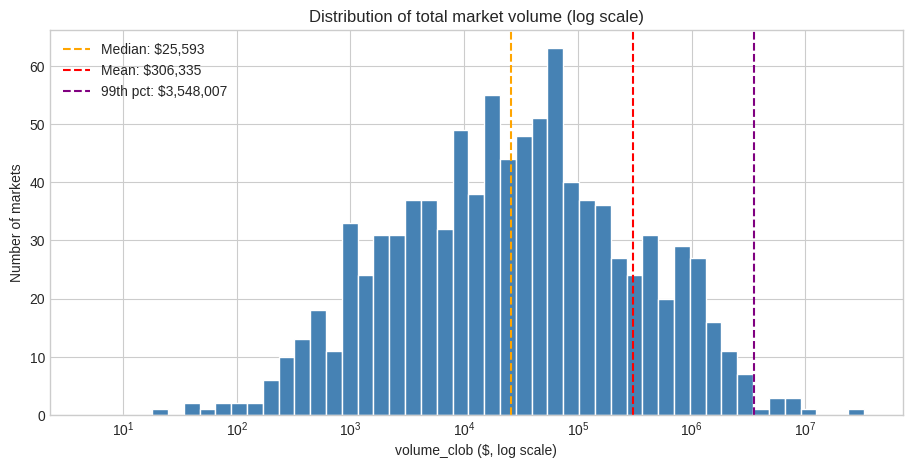

Not shown: 24 markets with zero volume

Q1. Share of markets below each volume level:
  exactly $0       2.4%
  under $100       3.2%
  under $1,000    10.9%
  under $10,000   36.2%

Q2. Top 1% (10 markets) hold 37.9% of total volume
    Top 10% (99 markets) hold 78.4%

Q3. 2 markets above $20,186,999 (unusually large on a log scale):


,title,event_slug,volume_clob,closed
325,Will Richard Grenell be the leader of Venezuela end of 2026?,venezuela-leader-end-of-2026,"$32,638,258",False
324,Will Frank Donovan be the leader of Venezuela end of 2026?,venezuela-leader-end-of-2026,"$25,796,083",False


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

v = pd.to_numeric(markets['volume_clob'], errors='coerce').dropna()
pos = v[v > 0]                     # log scale can't show zero
n_zero = (v <= 0).sum()

# --- Summary statistics ---
stats = pd.Series({
    'Mean':            v.mean(),
    'Median':          v.median(),
    '90th percentile': v.quantile(0.90),
    '95th percentile': v.quantile(0.95),
    '99th percentile': v.quantile(0.99),
    'Max':             v.max(),
})
display(stats.to_frame('volume_clob ($)').style.format('{:,.0f}'))
print(f"Mean is {v.mean() / v.median():,.1f}× the median")

# --- Histogram on a log scale ---
bins = np.logspace(np.log10(pos.min()), np.log10(pos.max()), 50)
fig, ax = plt.subplots(figsize=(11, 5))
ax.hist(pos, bins=bins, color='steelblue', edgecolor='white')
ax.set_xscale('log')
for name, val, col in [('Median', v.median(), 'orange'),
                       ('Mean', v.mean(), 'red'),
                       ('99th pct', v.quantile(0.99), 'purple')]:
    if val > 0:
        ax.axvline(val, ls='--', color=col, label=f'{name}: ${val:,.0f}')
ax.set(title='Distribution of total market volume (log scale)',
       xlabel='volume_clob ($, log scale)', ylabel='Number of markets')
ax.legend()
plt.show()
if n_zero:
    print(f"Not shown: {n_zero} markets with zero volume")

# --- Q1: Are most markets barely traded? ---
print("\nQ1. Share of markets below each volume level:")
for t in [0, 100, 1_000, 10_000]:
    label = 'exactly $0' if t == 0 else f'under ${t:,}'
    share = (v <= 0).mean() if t == 0 else (v < t).mean()
    print(f"  {label:<14} {share:6.1%}")

# --- Q2: Share of total volume from the top 1% of markets ---
s = v.sort_values(ascending=False)
k = max(1, int(np.ceil(len(s) * 0.01)))
print(f"\nQ2. Top 1% ({k} markets) hold {s.head(k).sum() / s.sum():.1%} of total volume")
print(f"    Top 10% ({int(np.ceil(len(s) * 0.10))} markets) hold "
      f"{s.head(int(np.ceil(len(s) * 0.10))).sum() / s.sum():.1%}")

# --- Q3: Unusually large markets (IQR rule on the log scale) ---
logv = np.log10(pos)
q1, q3 = logv.quantile([0.25, 0.75])
cutoff = 10 ** (q3 + 1.5 * (q3 - q1))
outliers = (markets.assign(volume_clob=v)
            .loc[lambda d: d['volume_clob'] > cutoff,
                 ['title', 'event_slug', 'volume_clob', 'closed']]
            .sort_values('volume_clob', ascending=False))
print(f"\nQ3. {len(outliers)} markets above ${cutoff:,.0f} (unusually large on a log scale):")
display(outliers.style.format({'volume_clob': '${:,.0f}'}))

##4. Random Cut

In [6]:
!pip -q install rrcf

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rrcf

from IPython.display import display

blind = wallet_features.drop(columns=['confirmed'], errors='ignore').copy()

assert blind['wallet'].is_unique, "Duplicate wallets found!"

behavior_cols = [
    'trade_count',
    'unique_markets',
    'total_notional',
    'avg_buy_price',
    'concentration',
    'max_single_buy',
    'wallet_age_days'
]

position_cols = behavior_cols + [
    'market_notional_ratio',
    'position_anomaly_ratio'
]

models = {
    'behavior': behavior_cols,
    'position': position_cols
}

log_cols = [
    'trade_count',
    'unique_markets',
    'total_notional',
    'max_single_buy',
    'wallet_age_days',
    'market_notional_ratio',
    'position_anomaly_ratio'
]

def prepare_features(df, columns):
    X = df[columns].apply(pd.to_numeric, errors='coerce')
    X = X.replace([np.inf, -np.inf], np.nan)

    for col in columns:
        if col in log_cols:
            X[col] = np.log1p(X[col].where(X[col] >= 0))

    X = X.fillna(X.median()).fillna(0)

    std = X.std(ddof=0).replace(0, 1)
    return (X - X.mean()) / std

print(f"Wallets: {len(blind):,}")
print(f"Behavior model: {len(behavior_cols)} features")
print(f"Position model: {len(position_cols)} features")

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Wallets: 55,952
Behavior model: 7 features
Position model: 9 features


/usr/local/lib/python3.13/dist-packages/rrcf/__init__.py:3: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


In [7]:
def run_rcf(X, passes=10, tree_size=256, seed=42):
    X = X.to_numpy(dtype=float)
    n = len(X)

    total = np.zeros(n)
    counts = np.zeros(n)

    rng = np.random.default_rng(seed)

    for p in range(passes):
        perm = rng.permutation(n)
        chunks = np.array_split(
            perm, max(1, int(np.ceil(n / tree_size)))
        )

        for chunk in chunks:
            tree = rrcf.RCTree(
                X[chunk],
                index_labels=chunk
            )

            for leaf in tree.leaves:
                total[leaf] += tree.codisp(leaf)
                counts[leaf] += 1

        print(f"Pass {p+1}/{passes} complete")

    return total / np.maximum(counts, 1)


TOP_PCT = 0.01
K = int(np.ceil(len(blind) * TOP_PCT))

pred = blind.copy()
standardized = {}

for name, columns in models.items():
    print(f"\nRunning {name.upper()} RCF")

    X = prepare_features(blind, columns)
    standardized[name] = X

    scores = run_rcf(X, passes=10, tree_size=256)

    pred[f'{name}_score'] = scores
    pred[f'{name}_rank'] = (
        pd.Series(scores, index=pred.index)
        .rank(ascending=False, method='first')
        .astype(int)
    )

    pred[f'{name}_flagged'] = pred[f'{name}_rank'] <= K

# Consensus: average the ranks of the two models
pred['consensus_avg_rank'] = (
    pred['behavior_rank'] + pred['position_rank']
) / 2

pred['consensus_rank'] = (
    pred['consensus_avg_rank']
    .rank(ascending=True, method='first')
    .astype(int)
)

pred['consensus_flagged'] = pred['consensus_rank'] <= K

print(f"\nWallets scored: {len(pred):,}")
print(f"Top 1% flagged per model: {K:,}")


Running BEHAVIOR RCF
Pass 1/10 complete
Pass 2/10 complete
Pass 3/10 complete
Pass 4/10 complete
Pass 5/10 complete
Pass 6/10 complete
Pass 7/10 complete
Pass 8/10 complete
Pass 9/10 complete
Pass 10/10 complete

Running POSITION RCF
Pass 1/10 complete
Pass 2/10 complete
Pass 3/10 complete
Pass 4/10 complete
Pass 5/10 complete
Pass 6/10 complete
Pass 7/10 complete
Pass 8/10 complete
Pass 9/10 complete
Pass 10/10 complete

Wallets scored: 55,952
Top 1% flagged per model: 560


In [8]:
for name in ['behavior', 'position', 'consensus']:
    print(f"\nTOP 10: {name.upper()}")

    columns = [
        'wallet',
        'trade_count',
        'unique_markets',
        'total_notional',
        'concentration',
        'market_notional_ratio',
        'position_anomaly_ratio',
        f'{name}_rank'
    ]

    if name != 'consensus':
        columns.append(f'{name}_score')

    display(
        pred.nsmallest(10, f'{name}_rank')[columns].round(3)
    )

overlap = (
    pred['behavior_flagged'] &
    pred['position_flagged']
).sum()

print(f"\nFlagged by both RCF models: {overlap} / {K}")

folder = '/content/drive/MyDrive/STATSC161'

pred.to_csv(
    f'{folder}/wallet_rcf_blind_predictions.csv',
    index=False
)

print("Saved blind predictions!")


TOP 10: BEHAVIOR


,wallet,trade_count,unique_markets,total_notional,concentration,market_notional_ratio,position_anomaly_ratio,behavior_rank,behavior_score
38058,w_0b84724f95,30405,684,2.826426e+05,0.029,0.765,0.495,1,148.470
27299,w_4f5cbbd869,18933,415,5.326783e+06,0.085,0.522,7.796,2,107.029
43988,w_558c6206a8,35215,1177,1.325751e+07,0.062,0.764,8.718,3,102.565
10611,w_c6568f4454,59885,618,4.617485e+05,0.104,0.012,0.324,4,99.962
23338,w_c2d389d2bf,5084,419,5.797483e+05,0.080,0.159,4.351,5,99.128
19231,w_c8557e336e,529,4,1.969096e+06,0.534,0.138,0.952,6,98.950
18563,w_d9b5e6ea57,2979,144,4.563366e+05,0.149,0.037,1.571,7,97.781
23463,w_7e4c6e18a1,26261,425,3.379422e+05,0.055,0.065,0.650,8,91.901
34011,w_f1e4bf3c3d,8296,149,5.834879e+05,0.136,0.283,1.276,9,89.317
22812,w_48945c9ac3,8939,205,1.666177e+04,0.142,0.007,3.654,10,88.132



TOP 10: POSITION


,wallet,trade_count,unique_markets,total_notional,concentration,market_notional_ratio,position_anomaly_ratio,position_rank,position_score
25700,w_70249d8edc,10,5,6.159365e+03,0.404,0.211,2.021,1,165.250
30361,w_a00a1221f3,309,55,2.586704e+05,0.201,0.840,4.410,2,164.202
55085,w_0ad921959f,240,43,3.363520e+05,0.356,0.922,1.277,3,158.200
43988,w_558c6206a8,35215,1177,1.325751e+07,0.062,0.764,8.718,4,155.533
7393,w_ab7b2a7ce4,5,4,1.758469e+03,0.568,0.713,2.272,5,145.875
1981,w_d10eb42459,30,22,5.453100e+01,0.293,0.909,4.841,6,145.583
13737,w_771b28906a,77,18,1.905945e+04,0.191,0.502,2.105,7,144.864
30004,w_9db0c9cf6c,1313,43,3.529958e+06,0.430,0.372,2.722,8,142.135
37265,w_a75b0e4e5f,5394,390,2.784813e+05,0.071,0.451,13.933,9,141.518
17227,w_9fc38fe70e,121,17,1.870333e+04,0.309,0.819,3.524,10,137.800



TOP 10: CONSENSUS


,wallet,trade_count,unique_markets,total_notional,concentration,market_notional_ratio,position_anomaly_ratio,consensus_rank
43988,w_558c6206a8,35215,1177,1.325751e+07,0.062,0.764,8.718,1
38058,w_0b84724f95,30405,684,2.826426e+05,0.029,0.765,0.495,2
30004,w_9db0c9cf6c,1313,43,3.529958e+06,0.430,0.372,2.722,3
4130,w_cdb0462106,2548,116,2.662965e+05,0.151,0.865,1.704,4
245,w_fd83f80fd3,3430,107,1.305943e+06,0.368,0.270,15.071,5
27671,w_ffe4e3c96a,3929,299,2.650833e+05,0.067,1.000,1.675,6
23463,w_7e4c6e18a1,26261,425,3.379422e+05,0.055,0.065,0.650,7
19231,w_c8557e336e,529,4,1.969096e+06,0.534,0.138,0.952,8
10000,w_deaa3be4fc,1145,71,2.430703e+06,0.224,0.261,7.796,9
20740,w_5366542275,24854,176,3.607912e+06,0.182,0.441,1.270,10



Flagged by both RCF models: 197 / 560


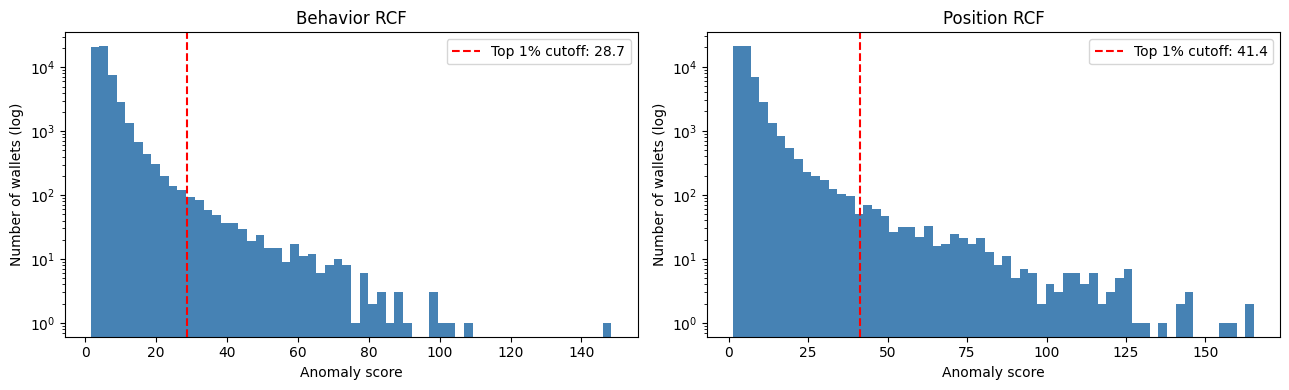

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, name in zip(axes, ['behavior', 'position']):
    scores = pred[f'{name}_score']

    cutoff = pred.loc[
        pred[f'{name}_flagged'],
        f'{name}_score'
    ].min()

    ax.hist(scores, bins=60, color='steelblue')
    ax.axvline(
        cutoff, color='red', linestyle='--',
        label=f'Top 1% cutoff: {cutoff:.1f}'
    )

    ax.set_yscale('log')
    ax.set_title(f'{name.title()} RCF')
    ax.set_xlabel('Anomaly score')
    ax.set_ylabel('Number of wallets (log)')
    ax.legend()

plt.tight_layout()
plt.show()

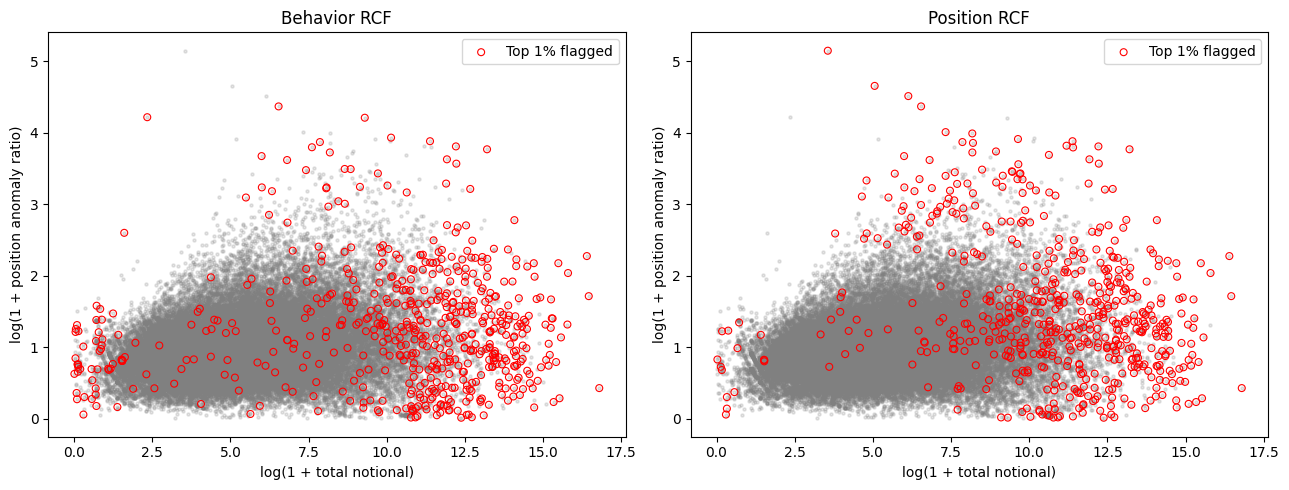

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

x = np.log1p(pred['total_notional'].clip(lower=0))
y = np.log1p(pred['position_anomaly_ratio'].clip(lower=0))

for ax, name in zip(axes, ['behavior', 'position']):
    flagged = pred[f'{name}_flagged']

    ax.scatter(
        x, y,
        s=5, alpha=0.2, color='gray'
    )

    ax.scatter(
        x[flagged], y[flagged],
        s=25, facecolors='none',
        edgecolors='red', linewidths=0.8,
        label='Top 1% flagged'
    )

    ax.set_title(f'{name.title()} RCF')
    ax.set_xlabel('log(1 + total notional)')
    ax.set_ylabel('log(1 + position anomaly ratio)')
    ax.legend()

plt.tight_layout()
plt.show()

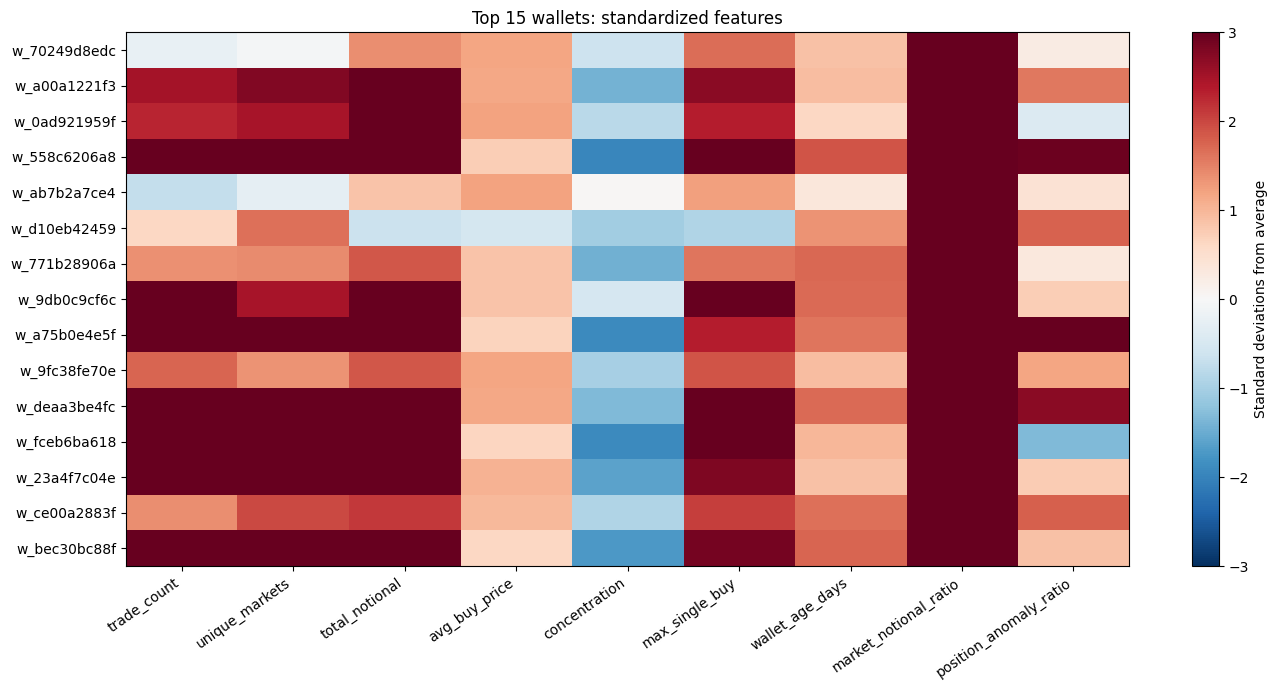

In [11]:
top = pred.nsmallest(15, 'position_rank')
z = standardized['position'].loc[top.index]

fig, ax = plt.subplots(figsize=(14, 7))

im = ax.imshow(
    z.to_numpy(),
    cmap='RdBu_r',
    vmin=-3,
    vmax=3,
    aspect='auto'
)

ax.set_xticks(range(len(z.columns)))
ax.set_xticklabels(z.columns, rotation=35, ha='right')

ax.set_yticks(range(len(top)))
ax.set_yticklabels(top['wallet'])

ax.set_title('Top 15 wallets: standardized features')

plt.colorbar(
    im, ax=ax,
    label='Standard deviations from average'
)

plt.tight_layout()
plt.show()

Total wallets: 55,952
Wallets with known labels: 55,952
Total confirmed wallets: 19
Baseline confirmed rate: 0.034%



,model,top_n,confirmed_found,confirmed_recall,confirmed_rate,lift_vs_random
0,behavior,20,0,0.0000,0.0000,0.0000
1,behavior,100,0,0.0000,0.0000,0.0000
2,behavior,560,1,0.0526,0.0018,5.2586
3,position,20,0,0.0000,0.0000,0.0000
4,position,100,0,0.0000,0.0000,0.0000
5,position,560,1,0.0526,0.0018,5.2586
6,consensus,20,0,0.0000,0.0000,0.0000
7,consensus,100,1,0.0526,0.0100,29.4484
8,consensus,560,3,0.1579,0.0054,15.7759


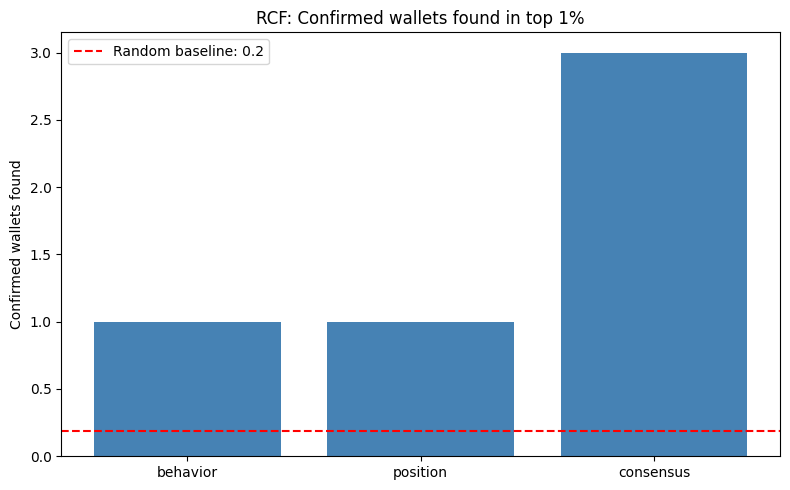


CONFIRMED WALLETS FOUND BY BEHAVIOR


,wallet,trade_count,total_notional,position_anomaly_ratio,behavior_rank
20983,w_5b2b2d0846,3753,3.900381e+06,1.095702,150



CONFIRMED WALLETS FOUND BY POSITION


,wallet,trade_count,total_notional,position_anomaly_ratio,position_rank
20983,w_5b2b2d0846,3753,3.900381e+06,1.095702,120



CONFIRMED WALLETS FOUND BY CONSENSUS


,wallet,trade_count,total_notional,position_anomaly_ratio,consensus_rank
20983,w_5b2b2d0846,3753,3.900381e+06,1.095702,49
2411,w_d1a074f023,199,6.532571e+04,0.772709,458
30878,w_bae5b984cf,870,2.972208e+05,1.575241,465


In [14]:
from sklearn.metrics import average_precision_score

truth = wallet_features[['wallet', 'confirmed']].copy()

truth['confirmed_label'] = (
    truth['confirmed']
    .astype('string')
    .str.strip()
    .str.lower()
    .map({'true': 1, 'false': 0, '1': 1, '0': 0})
)

results = pred.merge(
    truth[['wallet', 'confirmed_label']],
    on='wallet',
    how='left',
    validate='one_to_one'
)

valid = results.dropna(subset=['confirmed_label']).copy()
valid['confirmed_label'] = valid['confirmed_label'].astype(int)

total_confirmed = valid['confirmed_label'].sum()
base_rate = valid['confirmed_label'].mean()

print(f"Total wallets: {len(results):,}")
print(f"Wallets with known labels: {len(valid):,}")
print(f"Total confirmed wallets: {total_confirmed:,}")
print(f"Baseline confirmed rate: {base_rate:.3%}")
print()

rows = []

for name in ['behavior', 'position', 'consensus']:
    for top_n in [20, 100, K]:
        selected = valid[
            valid[f'{name}_rank'] <= top_n
        ]

        found = int(selected['confirmed_label'].sum())

        recall = (
            found / total_confirmed
            if total_confirmed > 0 else np.nan
        )

        confirmed_rate = (
            found / len(selected)
            if len(selected) > 0 else np.nan
        )

        lift = (
            confirmed_rate / base_rate
            if base_rate > 0 else np.nan
        )

        rows.append({
            'model': name,
            'top_n': top_n,
            'confirmed_found': found,
            'confirmed_recall': recall,
            'confirmed_rate': confirmed_rate,
            'lift_vs_random': lift
        })

comparison = pd.DataFrame(rows)

display(comparison.round(4))

top1_results = comparison[
    comparison['top_n'] == K
].copy()

plt.figure(figsize=(8, 5))

plt.bar(
    top1_results['model'],
    top1_results['confirmed_found'],
    color='steelblue'
)

expected = K * base_rate

plt.axhline(
    expected,
    color='red',
    linestyle='--',
    label=f'Random baseline: {expected:.1f}'
)

plt.ylabel('Confirmed wallets found')
plt.title('RCF: Confirmed wallets found in top 1%')
plt.legend()
plt.tight_layout()
plt.show()

for name in ['behavior', 'position', 'consensus']:
    print(f"\nCONFIRMED WALLETS FOUND BY {name.upper()}")

    hits = valid[
        (valid['confirmed_label'] == 1) &
        (valid[f'{name}_rank'] <= K)
    ]

    display(
        hits.sort_values(f'{name}_rank')[
            [
                'wallet',
                'trade_count',
                'total_notional',
                'position_anomaly_ratio',
                f'{name}_rank'
            ]
        ].head(20)
    )

In [ ]:
import re, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

def read_wallet_trades(dates):
    """Load one or more days of wallet trades, e.g. ['2026-10-03', '2026-10-04']."""
    dates = [dates] if isinstance(dates, str) else list(dates)
    for d in dates:
        if not re.fullmatch(r"\d{4}-\d{2}-\d{2}", d):
            raise ValueError(f"Bad date {d!r}; use the form 2026-10-03")
    urls = ", ".join(f"'{BASE}wallet_trades/trades-{d}.parquet'" for d in dates)
    return parquet_db.execute(f"SELECT * FROM read_parquet([{urls}])").df()

DATES = ['2026-10-03']          # add more dates for stronger outcome features
trades = read_wallet_trades(DATES)
trades.to_parquet(f"wallet_trades_{DATES[0]}_to_{DATES[-1]}.parquet")   # local copy; access ends Oct 29

trades = trades.rename(columns={'time': 'ts', 'dollars': 'usd'})
trades['ts'] = pd.to_datetime(trades['ts'], utc=True)
trades['is_buy'] = trades['side'].str.upper().eq('BUY')
print(f"{len(trades):,} trades | {trades['wallet'].nunique():,} wallets | "
      f"{trades['market'].nunique():,} markets")
display(trades.head())

970,880 trades | 35,363 wallets | 21,698 markets


,wallet,market,ts,side,outcome,price,size,usd,is_buy
0,0xeb10e414237546b18c6f1a87c2b5a7193f67aed3,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 12:45:35+00:00,BUY,Yes,0.37,4.756757,1.760000,True
1,0xbbecb03a1e605571630e08545809358781ae323d,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 12:45:35+00:00,BUY,Yes,0.37,115.000000,42.550000,True
2,0x7d4228c8e41f12fdc750fa852ac5f98132a10a1a,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 08:29:14+00:00,SELL,No,0.63,60.000000,37.800000,False
3,0xa67f112268a42b518edf6f4152bfe3ef6bb4afd4,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 08:29:14+00:00,BUY,Yes,0.37,20.000000,7.400000,True
4,0x143088b03e8512fc47a40ef8d67b82fa54318a86,0-ships-transit-hormuz-on-any-date-by-october-31,2026-10-03 06:44:26+00:00,BUY,No,0.66,65.151514,42.999999,True


In [ ]:
meta = query_db("""
    SELECT m.slug AS market, m.outcomes, r.resolved_yes, r.resolved_at
    FROM public.markets m
    LEFT JOIN public.resolutions r ON r.market_slug = m.slug
    WHERE m.slug = ANY(:m)
""", params={'m': trades['market'].unique().tolist()})

def first_outcome(o):
    if isinstance(o, str):
        try:
            o = json.loads(o)
        except ValueError:
            return None
    return str(o[0]).lower() if isinstance(o, list) and o else None

meta['first_outcome'] = meta['outcomes'].apply(first_outcome)
meta['resolved_at'] = pd.to_datetime(meta['resolved_at'], utc=True)
t = trades.merge(meta.drop(columns='outcomes'), on='market', how='left')

# Only count trades made before the market resolved, in markets with a known outcome
t['resolved'] = (t['resolved_yes'].notna() & t['first_outcome'].notna()
                 & (t['ts'] < t['resolved_at']))
bet_first = (t['outcome'].str.lower() == t['first_outcome']) == t['is_buy']
t['correct'] = t['resolved'] & (bet_first == t['resolved_yes'].fillna(False).astype(bool))

# Price paid for the side actually bet on (selling Yes at 0.90 = betting No at 0.10)
t['eff_price'] = np.where(t['is_buy'], t['price'], 1 - t['price'])
t['longshot'] = t['eff_price'] < 0.15

# Estimated profit if held to resolution: winners pay $1 per share
t['pnl'] = np.where(t['resolved'],
                    np.where(t['correct'], t['size'] * (1 - t['eff_price']),
                             -t['size'] * t['eff_price']), 0.0)
t['hrs_before'] = ((t['resolved_at'] - t['ts']).dt.total_seconds() / 3600).where(t['resolved'])

print(f"{t['resolved'].mean():.1%} of trades are in markets that have since resolved")
print(f"Win rate across resolved trades: {t.loc[t['resolved'], 'correct'].mean():.1%}")

16.2% of trades are in markets that have since resolved
Win rate across resolved trades: 54.0%


/tmp/ipykernel_2606/3171965655.py:24: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  t['correct'] = t['resolved'] & (bet_first == t['resolved_yes'].fillna(False).astype(bool))


In [ ]:
t['resolved_usd']     = t['usd'].where(t['resolved'], 0)
t['correct_usd']      = t['usd'].where(t['correct'], 0)
t['longshot_usd']     = t['usd'].where(t['longshot'], 0)
t['longshot_win_usd'] = t['usd'].where(t['longshot'] & t['correct'], 0)

w = t.groupby('wallet').agg(
    n_trades=('usd', 'size'), total_usd=('usd', 'sum'),
    median_trade=('usd', 'median'), max_trade=('usd', 'max'),
    n_markets=('market', 'nunique'), buy_share=('is_buy', 'mean'),
    first_ts=('ts', 'min'), last_ts=('ts', 'max'),
    resolved_trades=('resolved', 'sum'), resolved_usd=('resolved_usd', 'sum'),
    correct_usd=('correct_usd', 'sum'), longshot_usd=('longshot_usd', 'sum'),
    longshot_win_usd=('longshot_win_usd', 'sum'), pnl=('pnl', 'sum'),
    median_hrs_before=('hrs_before', 'median'),
)
safe = lambda a, b: (a / b.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)
w['active_hours']       = (w['last_ts'] - w['first_ts']).dt.total_seconds() / 3600
w['top_market_share']   = safe(t.groupby(['wallet', 'market'])['usd'].sum().groupby('wallet').max(), w['total_usd'])
w['longshot_share']     = safe(w['longshot_usd'], w['total_usd'])
w['win_rate']           = safe(w['correct_usd'], w['resolved_usd'])
w['longshot_win_share'] = safe(w['longshot_win_usd'], w['resolved_usd'])
w['pnl_per_dollar']     = safe(w['pnl'], w['resolved_usd'])

signed_log = lambda s: np.sign(s) * np.log1p(s.abs())
feat = pd.DataFrame({
    # behavior
    'log_n_trades':       np.log1p(w['n_trades']),
    'log_total_usd':      np.log1p(w['total_usd']),
    'log_max_trade':      np.log1p(w['max_trade']),
    'max_vs_median':      np.log1p(safe(w['max_trade'], w['median_trade'])),
    'log_n_markets':      np.log1p(w['n_markets']),
    'top_market_share':   w['top_market_share'],
    'buy_share':          w['buy_share'],
    'longshot_share':     w['longshot_share'],
    'log_active_hours':   np.log1p(w['active_hours']),
    # outcomes
    'win_rate':           w['win_rate'],
    'longshot_win_share': w['longshot_win_share'],
    'pnl_per_dollar':     signed_log(w['pnl_per_dollar']),
    'log_hrs_before':     np.log1p(w['median_hrs_before'].clip(lower=0)),
})

print(f"{len(w):,} wallets")
display(feat.describe().T.round(2))

35,363 wallets


,count,mean,std,min,25%,50%,75%,max
log_n_trades,35363.0,1.89,1.26,0.69,0.69,1.61,2.56,11.36
log_total_usd,35363.0,4.25,2.33,0.00,2.40,3.90,5.82,14.48
log_max_trade,35363.0,3.25,1.98,0.00,1.79,2.83,4.56,13.95
max_vs_median,35363.0,1.18,0.82,0.69,0.69,0.80,1.34,13.13
log_n_markets,35363.0,1.61,1.02,0.69,0.69,1.39,2.20,8.01
top_market_share,35363.0,0.60,0.35,0.00,0.28,0.55,1.00,1.00
buy_share,35363.0,0.82,0.28,0.00,0.67,1.00,1.00,1.00
longshot_share,35363.0,0.16,0.28,0.00,0.00,0.00,0.26,1.00
log_active_hours,35363.0,1.39,1.25,0.00,0.00,1.43,2.64,3.22
win_rate,15978.0,0.54,0.39,0.00,0.14,0.50,1.00,1.00


In [ ]:
import rrcf          # !pip install rrcf  if needed

MIN_TRADES   = 5     # total trades
MIN_RESOLVED = 3     # trades in markets with a known outcome
PASSES       = 20    # each wallet is scored this many times; try 5 first to check speed
TREE_SIZE    = 256

keep = (w['n_trades'] >= MIN_TRADES) & (w['resolved_trades'] >= MIN_RESOLVED)
F = feat[keep].fillna(feat[keep].median())
X = ((F - F.mean()) / F.std(ddof=0).replace(0, 1)).to_numpy()
n = len(X)
print(f"Scoring {n:,} of {len(w):,} wallets")

rng = np.random.default_rng(42)
total, counts = np.zeros(n), np.zeros(n)
for p in range(PASSES):
    perm = rng.permutation(n)
    for chunk in np.array_split(perm, max(1, n // TREE_SIZE)):
        tree = rrcf.RCTree(X[chunk], index_labels=chunk)
        for leaf in tree.leaves:
            total[leaf] += tree.codisp(leaf)
            counts[leaf] += 1
    print(f"  pass {p + 1}/{PASSES}")

w['anomaly_score'] = pd.Series(total / np.maximum(counts, 1), index=F.index)
threshold = w['anomaly_score'].quantile(0.99)          # top 1%
w['flagged'] = w['anomaly_score'] >= threshold
print(f"Flagged {w['flagged'].sum()} wallets (score ≥ {threshold:.1f})")

show = ['n_trades', 'total_usd', 'n_markets', 'top_market_share', 'longshot_share',
        'win_rate', 'longshot_win_share', 'pnl', 'median_hrs_before', 'anomaly_score']
display(w.sort_values('anomaly_score', ascending=False)[show].head(15)
          .style.format({'total_usd': '${:,.0f}', 'pnl': '${:,.0f}', 'anomaly_score': '{:.1f}',
                         'top_market_share': '{:.0%}', 'longshot_share': '{:.0%}',
                         'win_rate': '{:.0%}', 'longshot_win_share': '{:.0%}',
                         'median_hrs_before': '{:.1f}'}))

Scoring 6,865 of 35,363 wallets
  pass 1/20
  pass 2/20
  pass 3/20
  pass 4/20
  pass 5/20
  pass 6/20
  pass 7/20
  pass 8/20
  pass 9/20
  pass 10/20
  pass 11/20
  pass 12/20
  pass 13/20
  pass 14/20
  pass 15/20
  pass 16/20
  pass 17/20
  pass 18/20
  pass 19/20
  pass 20/20
Flagged 69 wallets (score ≥ 38.4)


,n_trades,total_usd,n_markets,top_market_share,longshot_share,win_rate,longshot_win_share,pnl,median_hrs_before,anomaly_score
wallet,,,,,,,,,,
0xb9150572b525c5a5ed082b0d19d4beac13ecc6bd,9,$153,7,52%,17%,62%,62%,$175,416.7,172.6
0x4647e4b34f072466bb0112b923d6b864b8693c74,8,$75,6,27%,87%,64%,64%,$326,62.2,150.0
0xa9c7a4a7683e42ae25db64527e436d9018862d62,5,$559,1,100%,82%,100%,82%,"$4,179",409.3,144.0
0x3bfbd331762ce2202aa63d03835b3ab8a59e4148,19,"$1,402",17,22%,21%,100%,48%,"$1,828",2.6,138.2
0x75d3796d1964c4db99c3e104b6a538514db81dc8,85442,"$100,427",43,20%,3%,70%,0%,$-277,2.0,135.4
0xcd4e3a137942770e7849e42260bd91c9b689eeb6,9,$76,7,23%,25%,100%,65%,$29,115.3,133.1
0x8016d58cb7dfaea4d58415df343020499b4ba2bf,16,$160,8,51%,59%,72%,72%,$57,2.8,133.0
0x24960c6a652099f60f7b6cd26efbc5f5946e65f3,15,$658,6,34%,24%,41%,41%,$-49,118.5,126.1
0x0a9476c7b4e4a11b4a71aa594a4ba10d14796e6b,15,"$4,112",8,23%,30%,58%,36%,$95,1.4,122.0


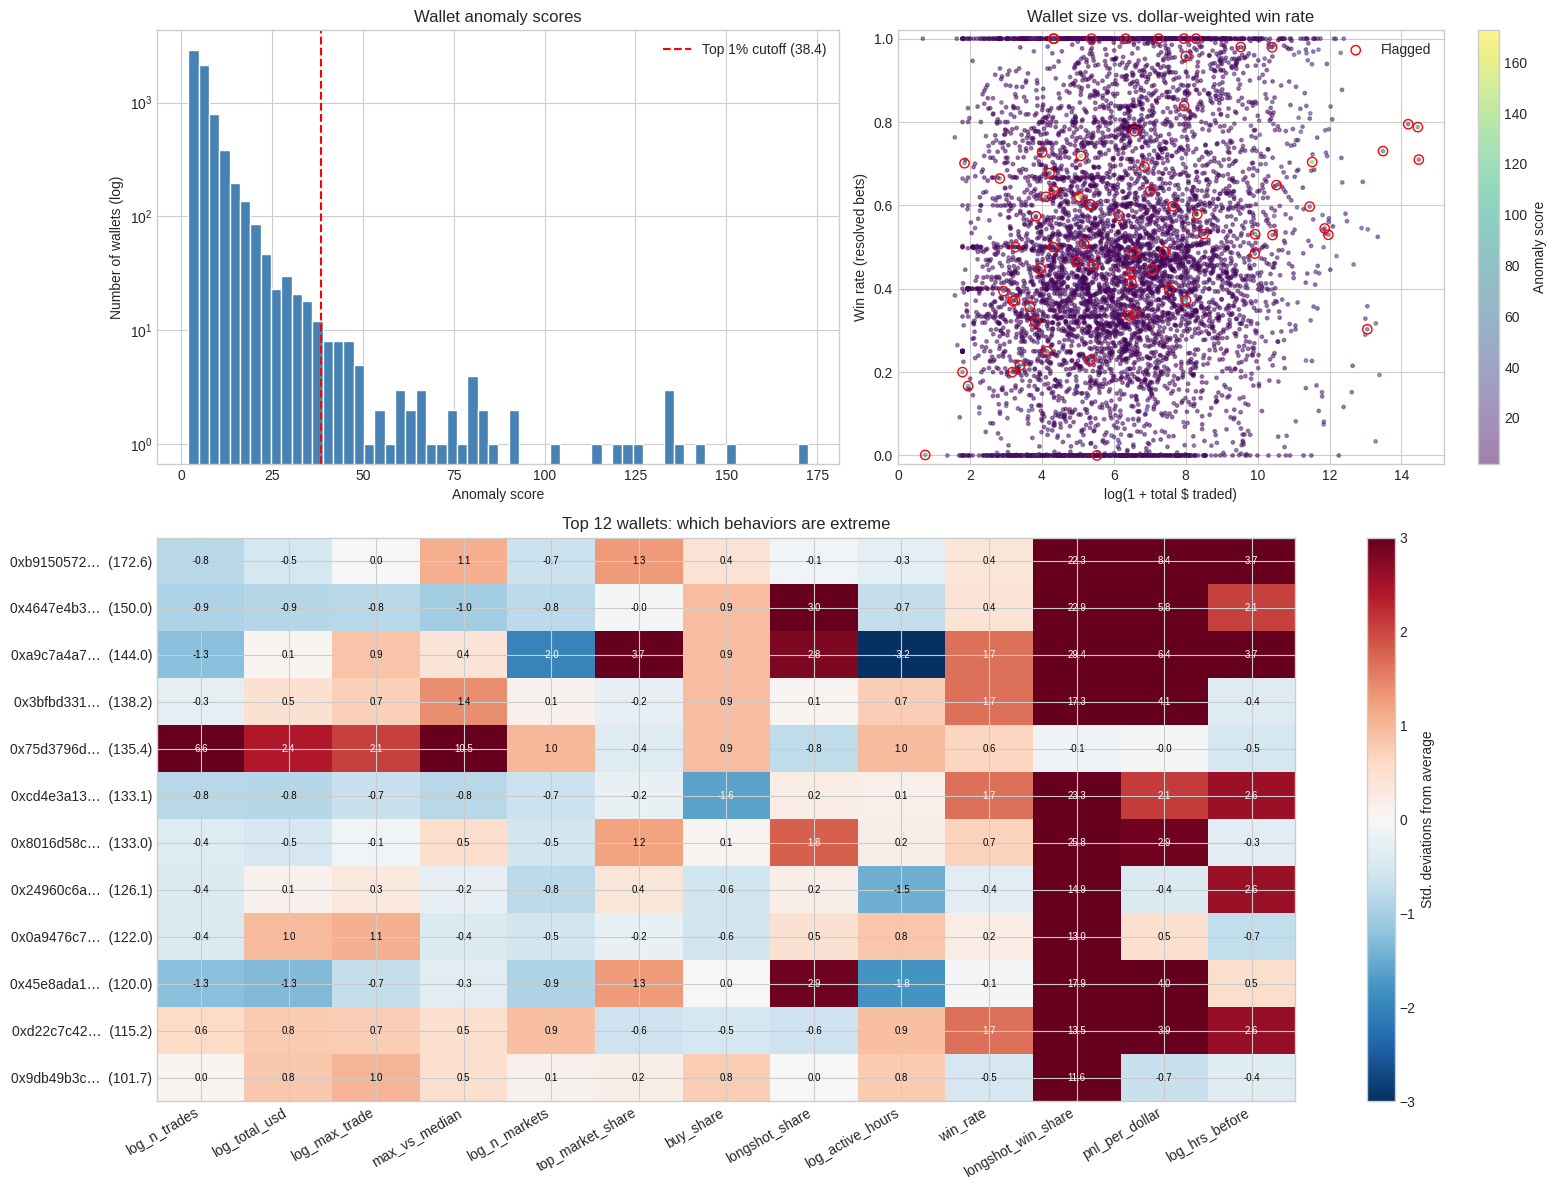

In [ ]:
top = w.nlargest(12, 'anomaly_score')
d = F.join(w[['anomaly_score', 'flagged', 'win_rate', 'total_usd']], rsuffix='_raw')

fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(2, 2, height_ratios=[1, 1.3])

# (a) Score distribution
ax = fig.add_subplot(gs[0, 0])
ax.hist(w['anomaly_score'].dropna(), bins=60, color='steelblue', edgecolor='white')
ax.axvline(threshold, color='red', ls='--', label=f'Top 1% cutoff ({threshold:.1f})')
ax.set(title='Wallet anomaly scores', xlabel='Anomaly score',
       ylabel='Number of wallets (log)', yscale='log')
ax.legend()

# (b) Size vs. win rate: big, accurate wallets are the classic insider profile
ax = fig.add_subplot(gs[0, 1])
sc = ax.scatter(d['log_total_usd'], d['win_rate_raw'], c=d['anomaly_score'],
                cmap='viridis', s=6, alpha=0.5)
ax.scatter(d.loc[d['flagged'], 'log_total_usd'], d.loc[d['flagged'], 'win_rate_raw'],
           s=45, facecolors='none', edgecolors='red', lw=1, label='Flagged')
fig.colorbar(sc, ax=ax, label='Anomaly score')
ax.set(title='Wallet size vs. dollar-weighted win rate',
       xlabel='log(1 + total $ traded)', ylabel='Win rate (resolved bets)', ylim=(-0.02, 1.02))
ax.legend()

# (c) Why each top wallet was flagged
ax = fig.add_subplot(gs[1, :])
z = pd.DataFrame(X, index=F.index, columns=F.columns).loc[top.index]
im = ax.imshow(z.to_numpy(), cmap='RdBu_r', vmin=-3, vmax=3, aspect='auto')
ax.set_xticks(range(z.shape[1]), z.columns, rotation=30, ha='right')
ax.set_yticks(range(len(z)), [f"{i[:10]}…  ({s:.1f})" for i, s in zip(top.index, top['anomaly_score'])])
for r in range(z.shape[0]):
    for c in range(z.shape[1]):
        v = z.iat[r, c]
        ax.text(c, r, f"{v:.1f}", ha='center', va='center', fontsize=7,
                color='white' if abs(v) > 1.5 else 'black')
fig.colorbar(im, ax=ax, label='Std. deviations from average')
ax.set_title('Top 12 wallets: which behaviors are extreme')

plt.tight_layout()
plt.show()

In [ ]:
labels = pd.read_csv('wallet_features.csv')
LABEL_WALLET_COL = 'wallet'                      # change to the CSV's column name
confirmed_ids = set(labels.loc[labels['confirmed'].astype(str).str.lower().isin(['true', '1', 'yes']),
                               LABEL_WALLET_COL].astype(str).str.lower())

w['confirmed'] = w.index.str.lower().isin(confirmed_ids)
w['rank_pct'] = w['anomaly_score'].rank(ascending=False, pct=True)
conf = w[w['confirmed']]
print(f"{len(confirmed_ids)} confirmed wallets; {len(conf)} traded on these dates; "
      f"{conf['anomaly_score'].notna().sum()} met the scoring thresholds")
display(conf[['n_trades', 'total_usd', 'win_rate', 'anomaly_score', 'rank_pct']].sort_values('rank_pct'))

for k in [0.01, 0.05, 0.10]:
    print(f"Top {k:.0%} of scores catches {(conf['rank_pct'] <= k).mean():.0%} "
          f"of scored confirmed wallets (random: {k:.0%})")

FileNotFoundError: [Errno 2] No such file or directory: 'wallet_features.csv'

## 10. Team presentation and next research stage

### A clear presentation story
1. **Data:** A Polymarket block sample, one row per market snapshot; distinguish this from a trade or a trader.
2. **Quality:** Show the missingness chart and filtering funnel. Explain that an open flag alone did not imply a future end date.
3. **EDA:** Show date-sensitive spread distributions and reported-volume concentration with the coverage denominator.
4. **Model:** Explain the four features, log transforms, scaling, and K comparison. Show cluster medians and the PCA view.
5. **Conclusion:** We found groups of market conditions and generated review leads. We did not classify or verify insider trading. Report how seed, time-feature, and event-level checks change assignments.

### What is needed to study possible informed trading properly?
The current fields cannot attribute behavior to a trader. Ask the professor whether the dataset also contains **verified executed trades**, trader/wallet identifiers, timestamps, buy/sell definitions, contract/outcome mappings, and historical quotes/order-book data. Obtain event-resolution times and timestamped public-news releases. Keep uncertainty about whether multiple wallets belong to one person.

A suitable future row could be **one wallet–market observation over a fixed window ending before a public event**. Candidate features include trade-size deviation from that wallet’s earlier baseline, pre-event position changes, timing relative to news, and concentration across related markets. Compute these only after feed semantics and sufficient historical coverage are confirmed. Never treat an asset ID as a wallet. Final profit and outcomes belong in later evaluation, not in features pretending to predict before the event.

**Validation plan:** Split chronologically, prevent related events/wallets from leaking across evaluation groups as appropriate to your question, fit transforms and choose K on training/development data only, and evaluate once on a held-out period. If verified case labels become available, assess precision/recall and review false positives against simple baselines; rare cases make raw accuracy misleading. Unlabeled cases are not automatically confirmed negatives. Never create “ground truth” by labeling the farthest 5% as insiders and then report accuracy against those same labels. Without verified labels, report cluster stability and documented review findings only.

### Your controls for experiments
- `PM_BLOCK_PERCENT`: sample size. Change it in Step 1 and rerun all new steps. A different sample may change the answer.
- `PM_SEED`: repeatability, not a guarantee across database updates.
- `PM_INCLUDE_VOLUME`: optional, coverage-gated features. Rerun from Step 5 afterward.
- `PM_K_OVERRIDE`: manually choose a tested K. Rerun from Step 6 afterward.
- The 95th-percentile cutoff in Step 8: a review-budget setting, not a scientific insider threshold.

### Run order and preserving work
For this Polymarket-only path, run the original installation and connection cells, then **this new section only**. Skip the earlier endpoint-verification and two-platform EDA cells. In the existing connection cell, enter the Polymarket password and press Enter at the unused Kalshi prompt. The new analysis never queries Kalshi. Do not use Run all if you want to skip the earlier comparison.

Download the Step 9 ZIP before the runtime disappears. To revisit a saved sample after uploading/unzipping it in Colab, use `pd.read_parquet` to load `market_sample.parquet` into `pm_raw`, restore `PM_AS_OF` from `manifest.json`, import the Step 1 libraries and restore settings, then run from Step 2. Do not reread the live database if you intend to reproduce the saved run. The feature CSV and saved scaler/model also preserve the exact fitted representation.

In [ ]:
# Query to see all tables in the public schema of the database
available_tables = query_db("""
    SELECT table_name, table_type
    FROM information_schema.tables
    WHERE table_schema = 'public'
    ORDER BY table_name;
""")

display(available_tables)

,table_name,table_type
0,events,BASE TABLE
1,market_hourly,BASE TABLE
2,markets,BASE TABLE
3,resolutions,BASE TABLE
4,wallet_pseudonym_map,BASE TABLE


In [ ]:
# 1. Show columns and data types for wallet_pseudonym_map
columns_info = query_db("""
    SELECT column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'public' AND table_name = 'wallet_pseudonym_map'
    ORDER BY ordinal_position;
""")
print("=== wallet_pseudonym_map Schema ===")
display(columns_info)

# 2. Preview the first 5 rows
preview_rows = query_db("""
    SELECT *
    FROM public.wallet_pseudonym_map
    LIMIT 5;
""")
print("\n=== wallet_pseudonym_map Preview ===")
display(preview_rows)

=== wallet_pseudonym_map Schema ===


,column_name,data_type
0,real_wallet,bytea
1,pseudo_wallet,bytea
2,created_at,timestamp with time zone



=== wallet_pseudonym_map Preview ===


,real_wallet,pseudo_wallet,created_at
0,"[b'\xe3', b'\xa5', b'j', b'\xec', b'm', b'\x81...","[b'U', b'\x07', b'\xf9', b'z', b'\x81', b'[', ...",2026-10-04 06:08:17.746273+00:00
1,"[b'K', b'\x8a', b'\xe0', b'\x11', b'\x17', b'k...","[b""'"", b'v', b';', b'\xb9', b'K', b'\xd6', b'/...",2026-10-04 06:08:17.746273+00:00
2,"[b'\x13', b'\xf3', b'\xca', b'\x8a', b'\x18', ...","[b'\x8f', b'\xff', b'\xb2', b'\x14', b'J', b'>...",2026-10-04 06:08:17.746273+00:00
3,"[b'\xad', b'S', b'S', b'\xaf', b'\xe3', b'\x0c...","[b'\x1b', b'e', b',', b'\xb2', b'\xf3', b'D', ...",2026-10-04 06:08:17.746273+00:00
4,"[b'\xa8', b'o', b'h', b'}', b'~', b'\xed', b'\...","[b'\x13', b'\xaf', b'l', b'\xa8', b'\x98', b'\...",2026-10-04 06:08:17.746273+00:00


In [ ]:
# Retrieve and display all column names and data types for 'public.markets'
markets_schema = query_db("""
    SELECT column_name, data_type
    FROM information_schema.columns
    WHERE table_schema = 'public' AND table_name = 'markets'
    ORDER BY ordinal_position;
""")
print("=== public.markets Table Schema ===")
display(markets_schema)

# Retrieve a small preview of several diverse fields from the table
markets_preview = query_db("""
    SELECT slug, title, active, closed, volume_clob, best_bid, best_ask, last_trade_price
    FROM public.markets
    WHERE volume_clob IS NOT NULL
    LIMIT 5;
""")
print("\n=== public.markets Data Preview ===")
display(markets_preview)

=== public.markets Table Schema ===


,column_name,data_type
0,slug,text
1,title,text
2,condition_id,text
3,synced_at,bigint
4,start_date,timestamp with time zone
5,end_date,timestamp with time zone
6,active,boolean
7,closed,boolean
8,archived,boolean
9,created_at,timestamp with time zone



=== public.markets Data Preview ===


,slug,title,active,closed,volume_clob,best_bid,best_ask,last_trade_price
0,wta-doubles-huntsin-errapao-2026-10-17-set-han...,Set Handicap: Hunter/Siniakova (-1.5) vs Erran...,True,False,6.944442,0.23,0.54,NaN
1,zec-updown-5m-1792307400,"ZCash Up or Down - October 18, 3:10AM-3:15AM ET",True,False,0.000000,0.00,1.00,0.0
2,sol-updown-5m-1792307400,"Solana Up or Down - October 18, 3:10AM-3:15AM ET",True,False,0.000000,0.00,1.00,0.0
3,xrp-updown-5m-1792307400,"XRP Up or Down - October 18, 3:10AM-3:15AM ET",True,False,0.000000,0.00,1.00,0.0
4,btc-updown-5m-1792307400,"Bitcoin Up or Down - October 18, 3:10AM-3:15AM ET",True,False,0.000000,0.00,1.00,0.0
